In [2]:
import sys
import subprocess

print("Versión de Python:")
print(sys.version)

print("\nVersión de Java:")
resultado = subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True
)
print(resultado.stderr or resultado.stdout)

Versión de Python:
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

Versión de Java:
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)



In [3]:
%pip install pyspark==4.0.1 openpyxl==3.1.5

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.2/434.2 MB 12.3 MB/s  0:00:23
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyspark: filename=pyspark-4.0.1-py2.py3-none-any.whl size=434813857 sha256=1dc252497d8cf42faecf7ad2fd18849805f3a47ff5b474376f9389e90378c32c
  Stored in directory: /root/.cache/pip/wheels/00/e3/92/8594f4cee2c9fd4ad82fe85e4bf2559ab8ea84ef19b1dd3d15
Successfully built pyspark
  Attempting uninstall: pyspark
    Found existing installation: pyspark 4.0.4
    Uninstalling pyspark-4.0.4:
      Successfully uninstalled pyspark-4.0.4


In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Tarea3_OnlineRetail_Diana")
    .master("local[*]")
    .getOrCreate()
)

print("Versión de Spark:", spark.version)

# Prueba sencilla: contar diez registros
cantidad = spark.range(10).count()
print("Registros procesados en la prueba:", cantidad)

assert cantidad == 10
print("Spark funciona correctamente.")

Versión de Spark: 4.0.1
Registros procesados en la prueba: 10
Spark funciona correctamente.


In [2]:
from google.colab import files

archivos_subidos = files.upload()

print("\nArchivos cargados:")
for nombre in archivos_subidos:
    print(nombre)

Saving Ventas_Online_Retail_UCI.xlsx to Ventas_Online_Retail_UCI.xlsx

Archivos cargados:
Ventas_Online_Retail_UCI.xlsx


In [3]:
import pandas as pd

archivo = "Ventas_Online_Retail_UCI.xlsx"

datos_excel = pd.read_excel(
    archivo,
    sheet_name="Online Retail",
    engine="openpyxl",
    dtype={
        "InvoiceNo": str,
        "StockCode": str,
        "CustomerID": str
    }
)

print("Número de registros:", len(datos_excel))
print("Número de columnas:", len(datos_excel.columns))
print("\nPrimeras cinco filas:")
display(datos_excel.head())

Número de registros: 541909
Número de columnas: 8

Primeras cinco filas:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [4]:
# Crear un CSV intermedio sin eliminar registros
ruta_csv = "/content/online_retail.csv"

datos_excel.to_csv(
    ruta_csv,
    index=False,
    date_format="%Y-%m-%d %H:%M:%S"
)

# Definir el tipo de cada columna
esquema = """
    InvoiceNo STRING,
    StockCode STRING,
    Description STRING,
    Quantity INT,
    InvoiceDate TIMESTAMP,
    UnitPrice DECIMAL(18,4),
    CustomerID STRING,
    Country STRING
"""

# Leer los datos con Apache Spark
df = (
    spark.read
    .option("header", True)
    .option("multiLine", True)
    .option("escape", '"')
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .option("mode", "FAILFAST")
    .schema(esquema)
    .csv(ruta_csv)
    .cache()
)

total_inicial = df.count()

print("Registros cargados en Spark:", total_inicial)
print("Columnas:", len(df.columns))

assert total_inicial == len(datos_excel), "Revisar: los conteos no coinciden."

print("\nTipos de datos:")
df.printSchema()

print("\nPrimeras cinco filas en Spark:")
df.show(5, truncate=30)

Registros cargados en Spark: 541909
Columnas: 8

Tipos de datos:
root
 |-- InvoiceNo: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: timestamp (nullable = true)
 |-- UnitPrice: decimal(18,4) (nullable = true)
 |-- CustomerID: string (nullable = true)
 |-- Country: string (nullable = true)


Primeras cinco filas en Spark:
+---------+---------+------------------------------+--------+-------------------+---------+----------+--------------+
|InvoiceNo|StockCode|                   Description|Quantity|        InvoiceDate|UnitPrice|CustomerID|       Country|
+---------+---------+------------------------------+--------+-------------------+---------+----------+--------------+
|   536365|   85123A|WHITE HANGING HEART T-LIGHT...|       6|2010-12-01 08:26:00|   2.5500|     17850|United Kingdom|
|   536365|    71053|           WHITE METAL LANTERN|       6|2010-12-01 08:26:00|   

In [5]:
from pyspark.sql import functions as F

# Contar valores nulos o textos vacíos por columna
expresiones = []

for columna, tipo in df.dtypes:
    faltante = F.col(columna).isNull()

    if tipo == "string":
        faltante = faltante | (F.trim(F.col(columna)) == "")

    expresiones.append(
        F.sum(F.when(faltante, 1).otherwise(0)).alias(columna)
    )

print("Valores faltantes por columna:")
df.select(*expresiones).show(truncate=False)

# Contar repeticiones exactas considerando las ocho columnas
duplicados = total_inicial - df.dropDuplicates().count()
print("Filas repetidas adicionales:", duplicados)

print("\nRevisión de cantidades, precios y facturas:")
df.select(
    F.sum(F.when(F.col("Quantity") <= 0, 1).otherwise(0))
        .alias("Cantidad_no_positiva"),

    F.sum(F.when(F.col("UnitPrice") <= 0, 1).otherwise(0))
        .alias("Precio_no_positivo"),

    F.sum(
        F.when(
            F.upper(F.trim(F.col("InvoiceNo"))).startswith("C"), 1
        ).otherwise(0)
    ).alias("Filas_facturas_con_C")
).show(truncate=False)

Valores faltantes por columna:
+---------+---------+-----------+--------+-----------+---------+----------+-------+
|InvoiceNo|StockCode|Description|Quantity|InvoiceDate|UnitPrice|CustomerID|Country|
+---------+---------+-----------+--------+-----------+---------+----------+-------+
|0        |0        |1454       |0       |0          |0        |135080    |0      |
+---------+---------+-----------+--------+-----------+---------+----------+-------+

Filas repetidas adicionales: 5268

Revisión de cantidades, precios y facturas:
+--------------------+------------------+--------------------+
|Cantidad_no_positiva|Precio_no_positivo|Filas_facturas_con_C|
+--------------------+------------------+--------------------+
|10624               |2517              |9288                |
+--------------------+------------------+--------------------+



In [6]:
from pyspark.sql import functions as F

# 1. Conservar una copia de cada fila exactamente igual
df_sin_duplicados = df.dropDuplicates()
total_sin_duplicados = df_sin_duplicados.count()

# 2. Exigir los campos necesarios para este análisis
campos_necesarios = [
    "InvoiceNo", "StockCode", "Description",
    "Quantity", "InvoiceDate", "UnitPrice", "Country"
]

df_completo = df_sin_duplicados.dropna(subset=campos_necesarios)

# Excluir textos vacíos en los campos necesarios
for columna in ["InvoiceNo", "StockCode", "Description", "Country"]:
    df_completo = df_completo.filter(
        F.length(F.trim(F.col(columna))) > 0
    )

total_completo = df_completo.count()

# 3. Seleccionar cantidades y precios positivos,
#    excluyendo facturas que comienzan con C
df_ventas = df_completo.filter(
    (F.col("Quantity") > 0)
    & (F.col("UnitPrice") > 0)
    & (~F.upper(F.trim(F.col("InvoiceNo"))).startswith("C"))
)

# 4. Calcular el importe de cada línea
df_ventas = df_ventas.withColumn(
    "Importe",
    F.col("Quantity") * F.col("UnitPrice")
).cache()

total_final = df_ventas.count()

# 5. Mostrar las exclusiones por etapas, sin contarlas dos veces
print("Registros originales:", total_inicial)
print("Repeticiones retiradas:", total_inicial - total_sin_duplicados)
print("Excluidos por campos necesarios faltantes:",
      total_sin_duplicados - total_completo)
print("Excluidos por factura, cantidad o precio:",
      total_completo - total_final)
print("Registros finales para el análisis:", total_final)

print("\nEjemplos con el importe calculado:")
df_ventas.select(
    "InvoiceNo", "StockCode", "Quantity", "UnitPrice", "Importe"
).show(5, truncate=False)

Registros originales: 541909
Repeticiones retiradas: 5268
Excluidos por campos necesarios faltantes: 1454
Excluidos por factura, cantidad o precio: 10309
Registros finales para el análisis: 524878

Ejemplos con el importe calculado:
+---------+---------+--------+---------+-------+
|InvoiceNo|StockCode|Quantity|UnitPrice|Importe|
+---------+---------+--------+---------+-------+
|536373   |84029E   |6       |3.3900   |20.3400|
|536375   |37370    |6       |1.0600   |6.3600 |
|536381   |22261    |1       |0.8500   |0.8500 |
|536392   |22127    |12      |1.2500   |15.0000|
|536404   |21125    |12      |1.2500   |15.0000|
+---------+---------+--------+---------+-------+
only showing top 5 rows


In [7]:
from pyspark.sql import functions as F

resumen = df_ventas.agg(
    F.count("*").alias("Lineas_de_venta"),
    F.countDistinct("InvoiceNo").alias("Facturas_distintas"),
    F.countDistinct("StockCode").alias("Codigos_distintos"),
    F.countDistinct("Country").alias("Paises"),
    F.sum("Quantity").alias("Unidades"),
    F.round(F.sum("Importe"), 2).alias("Importe_total"),
    F.min("InvoiceDate").alias("Primera_fecha"),
    F.max("InvoiceDate").alias("Ultima_fecha")
)

resumen.show(truncate=False, vertical=True)

-RECORD 0---------------------------------
 Lineas_de_venta    | 524878              
 Facturas_distintas | 19960               
 Codigos_distintos  | 3922                
 Paises             | 38                  
 Unidades           | 5572420             
 Importe_total      | 10642110.80         
 Primera_fecha      | 2010-12-01 08:26:00 
 Ultima_fecha       | 2011-12-09 12:50:00 



In [8]:
ventas_por_producto = df_ventas.groupBy("StockCode").agg(
    F.min("Description").alias("Descripcion_referencia"),
    F.sum("Quantity").alias("Unidades"),
    F.round(F.sum("Importe"), 2).alias("Importe_total"),
    F.countDistinct("InvoiceNo").alias("Facturas")
)

top10_productos = ventas_por_producto.orderBy(
    F.desc("Unidades"),
    F.asc("StockCode")
).limit(10)

tabla_top10 = top10_productos.toPandas()
display(tabla_top10)

,StockCode,Descripcion_referencia,Unidades,Importe_total,Facturas
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
2,22197,POPCORN HOLDER,56898,51334.47,1392
3,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,535
4,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
5,85123A,CREAM HANGING HEART T-LIGHT HOLDER,37641,104462.75,2198
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,1320
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455
8,23084,RABBIT NIGHT LIGHT,30739,66870.03,994
9,22492,MINI PAINT SET VINTAGE,26633,16937.82,380


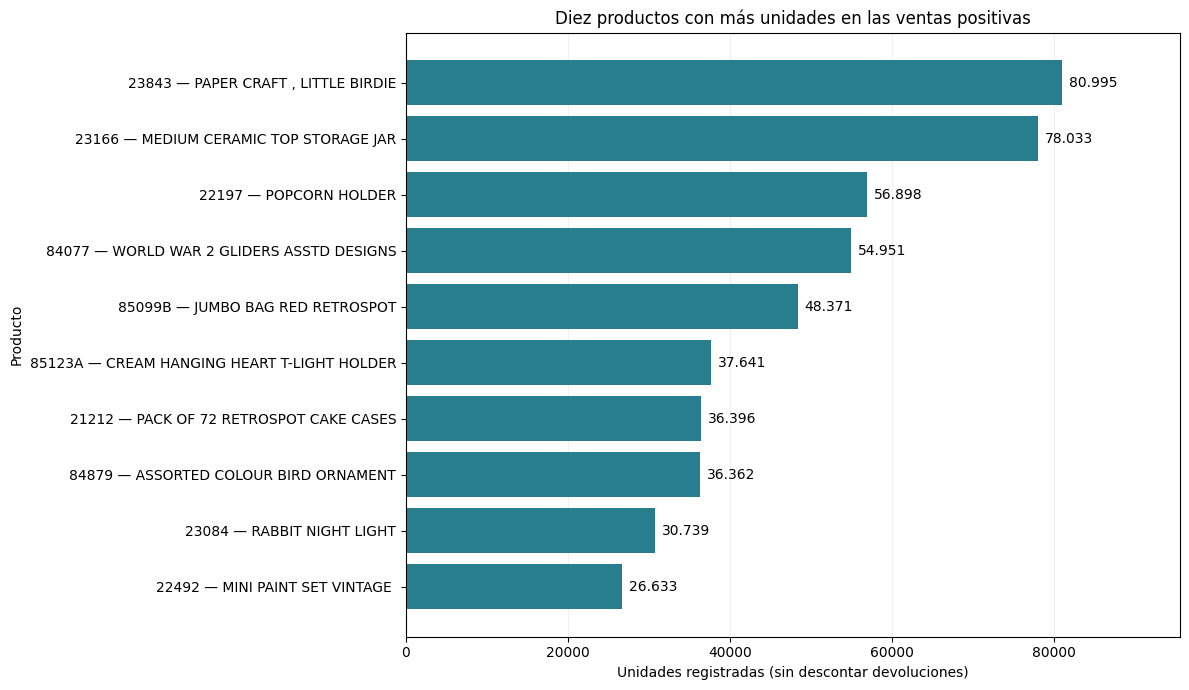

In [9]:
import matplotlib.pyplot as plt

grafica = tabla_top10.sort_values("Unidades", ascending=True)
etiquetas = (
    grafica["StockCode"] + " — " +
    grafica["Descripcion_referencia"]
)

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(etiquetas, grafica["Unidades"], color="#287D8E")
ax.bar_label(
    barras,
    labels=[f"{int(v):,}".replace(",", ".") for v in grafica["Unidades"]],
    padding=5
)

ax.set_title("Diez productos con más unidades en las ventas positivas")
ax.set_xlabel("Unidades registradas (sin descontar devoluciones)")
ax.set_ylabel("Producto")
ax.set_xlim(0, grafica["Unidades"].max() * 1.18)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("/content/top10_productos.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
from google.colab import files
files.download("/content/top10_productos.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
ventas_por_pais = df_ventas.groupBy("Country").agg(
    F.countDistinct("InvoiceNo").alias("Facturas"),
    F.sum("Quantity").alias("Unidades"),
    F.round(F.sum("Importe"), 2).alias("Importe_total")
)

top10_paises = ventas_por_pais.orderBy(
    F.desc("Importe_total"),
    F.asc("Country")
).limit(10)

tabla_paises = top10_paises.toPandas()
display(tabla_paises)

,Country,Facturas,Unidades,Importe_total
0,United Kingdom,18019,4646906,9001744.09
1,Netherlands,94,200361,285446.34
2,EIRE,288,147007,283140.52
3,Germany,457,119154,228678.40
4,France,392,112060,209625.37
5,Australia,57,83891,138453.81
6,Spain,90,27933,61558.56
7,Switzerland,54,30617,57067.60
8,Belgium,98,23237,41196.34
9,Sweden,36,36078,38367.83


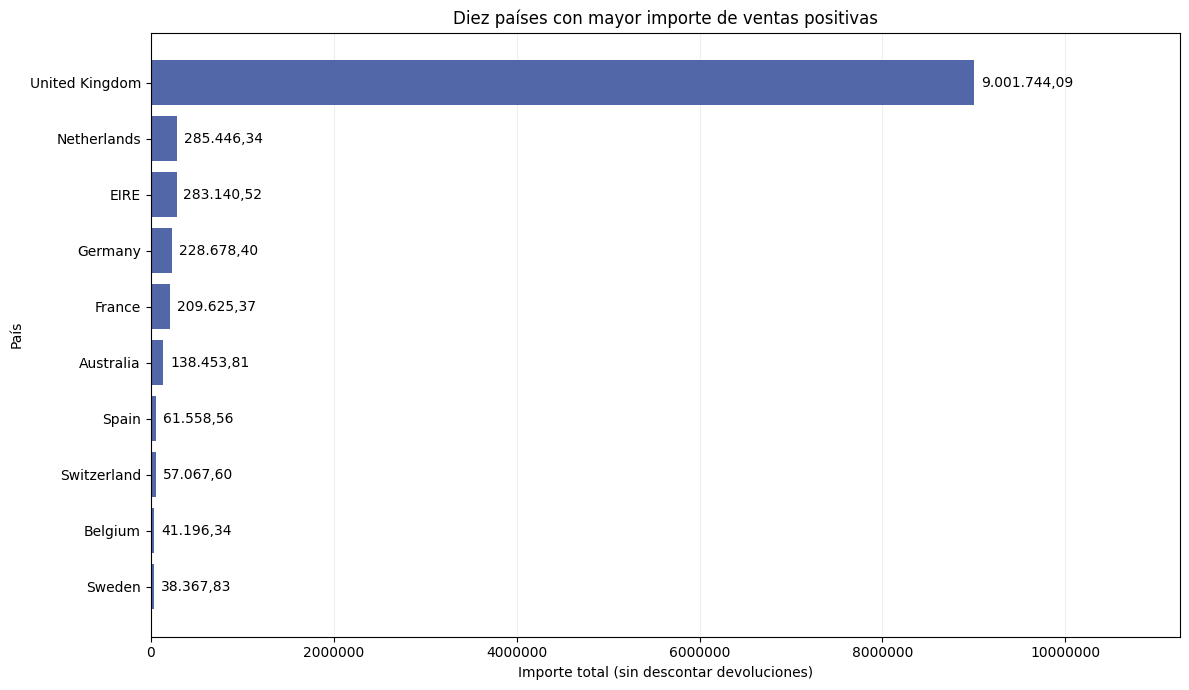

In [12]:
import matplotlib.pyplot as plt

grafica_paises = tabla_paises.sort_values("Importe_total").copy()
importes = grafica_paises["Importe_total"].astype(float)

fig, ax = plt.subplots(figsize=(12, 7))
barras = ax.barh(
    grafica_paises["Country"],
    importes,
    color="#5267A8"
)

etiquetas = [
    f"{v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    for v in importes
]
ax.bar_label(barras, labels=etiquetas, padding=5)

ax.set_title("Diez países con mayor importe de ventas positivas")
ax.set_xlabel("Importe total (sin descontar devoluciones)")
ax.set_ylabel("País")
ax.set_xlim(0, importes.max() * 1.25)
ax.ticklabel_format(style="plain", axis="x")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("/content/top10_paises.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
from google.colab import files
files.download("/content/top10_paises.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusiones del procesamiento por lotes

1. Se cargó el conjunto Online Retail con 541.909 registros y ocho columnas. Mediante PySpark se revisaron los datos faltantes, las repeticiones exactas y los valores de cantidades y precios.

2. Tras aplicar los criterios de limpieza, se conservaron 524.878 líneas de venta. Se eliminaron las repeticiones exactas y se excluyeron los registros con campos requeridos incompletos, cantidades o precios no positivos y facturas identificadas como cancelaciones.

3. Los registros seleccionados contienen 19.960 facturas distintas y 5.572.420 unidades. El importe acumulado fue de 10.642.110,80 y corresponde a ventas positivas sin descontar devoluciones.

4. Reino Unido presentó el mayor importe de ventas positivas con 9.001.744,09, seguido de Países Bajos con 285.446,34. Estos resultados muestran una concentración del importe en Reino Unido dentro del conjunto analizado.

5. El producto con código 23843 encabezó la clasificación por unidades con 80.995 unidades concentradas en una sola factura. Este resultado requiere cautela: una operación de gran volumen puede encabezar la clasificación sin representar compras frecuentes.

## Alcance de la práctica

La carga en Spark, la limpieza y las agregaciones corresponden al procesamiento por lotes. Se conservaron los registros sin CustomerID cuando cumplían los demás criterios, porque el análisis se realizó por producto y país. Los resultados describen las ventas positivas seleccionadas y no representan ingresos netos ni ganancias.